<a href="https://colab.research.google.com/github/mdnazishpatel/Machine_learning/blob/main/Custom_Datasets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Custom datasets in pytorch


In [2]:
import torch
from torch import nn


torch.__version__

'2.14.1+cu130'

In [3]:
device = "cuda" if torch.cuda.is_available() else "gpu"
device


'cuda'

In [4]:
!nvidia-smi

Tue Nov 24 15:35:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   52C    P8             10W /   70W |       3MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

### Getting data from food101 we are using subsets of it

In [12]:
import requests
import zipfile
from pathlib import Path

## setingup path to a data folder
data_path = Path("data/")
image_path = data_path / "pizza_steak_sushi"
#if image folder does not exist create one
if image_path.is_dir():
  print(f"{image_path} directory already exist...skipping download")
else:
  print(f"{image_path} does not exist, creating one...")
  image_path.mkdir(parents=True, exist_ok=True)
# download data (file)
with open(data_path / "pizza_steak_sushi.zip", "wb") as f:
  request = requests.get("https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi.zip")
  print(f"downloading data")
  f.write(request.content)
# unzip the data(file)
with zipfile.ZipFile(data_path / "pizza_steak_sushi.zip", "r") as zip_ref:
  print("unzipping file to get data")
  zip_ref.extractall(image_path)

data/pizza_steak_sushi directory already exist...skipping download
downloading data
unzipping file to get data


In [15]:
image_path

PosixPath('data/pizza_steak_sushi')

### Data preparation and data exploratation

In [16]:
import os
def walk_through_dir(dir_path):
  for dirpath, dirnames,filenames in os.walk(dir_path):
    print(f"there are {len(dirnames)} directories and {len(filenames)} images in {dirpath}")

In [18]:
walk_through_dir(image_path)

there are 2 directories and 0 images in data/pizza_steak_sushi
there are 3 directories and 0 images in data/pizza_steak_sushi/train
there are 0 directories and 78 images in data/pizza_steak_sushi/train/pizza
there are 0 directories and 72 images in data/pizza_steak_sushi/train/sushi
there are 0 directories and 75 images in data/pizza_steak_sushi/train/steak
there are 3 directories and 0 images in data/pizza_steak_sushi/test
there are 0 directories and 25 images in data/pizza_steak_sushi/test/pizza
there are 0 directories and 31 images in data/pizza_steak_sushi/test/sushi
there are 0 directories and 19 images in data/pizza_steak_sushi/test/steak


In [21]:
# setup train and test path

train_dir = image_path / "train"
test_dir = image_path / "test"


train_dir, test_dir

(PosixPath('data/pizza_steak_sushi/train'),
 PosixPath('data/pizza_steak_sushi/test'))

### Visualizing images

random image path:data/pizza_steak_sushi/train/steak/2707522.jpg
image class:steak
image height:512
image width:512


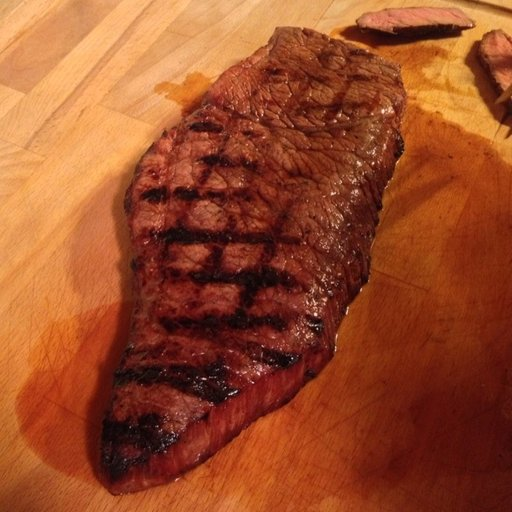

In [72]:

import matplotlib.pyplot as plt
import random
from  PIL import Image

# random.seed(42)

image_path_list = list(image_path.glob("*/*/*.jpg")) # dir->file->content


random_image_path = random.choice(image_path_list)

random_image_path

image_class = random_image_path.parent.stem


img = Image.open(random_image_path)

print(f"random image path:{random_image_path}")
print(f"image class:{image_class}")
print(f"image height:{img.height}")
print(f"image width:{img.width}")
img


(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

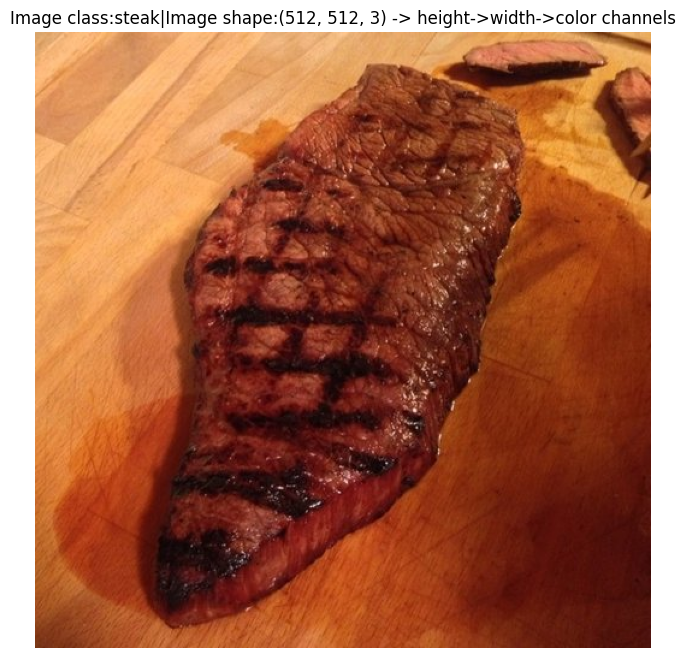

In [73]:
import numpy as np
import matplotlib.pyplot as plt


img_as_array = np.asarray(img)
plt.figure(figsize=(12,8))
plt.imshow(img_as_array)
plt.title(f"Image class:{image_class}|Image shape:{img_as_array.shape} -> height->width->color channels")
plt.axis(False)


### Transforming data into tensors
before using any kind of data turn it into tensors
`Datasets & DataLoaders`

In [82]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets, transforms



In [86]:
data_transform = transforms.Compose([
    #resize images
    transforms.Resize(size=(64,64)),
    #Flip the images
    transforms.RandomHorizontalFlip(p=0.5),
    #turning image into torch.tensor
    transforms.ToTensor()
])
data_transform(img).dtype

torch.float32

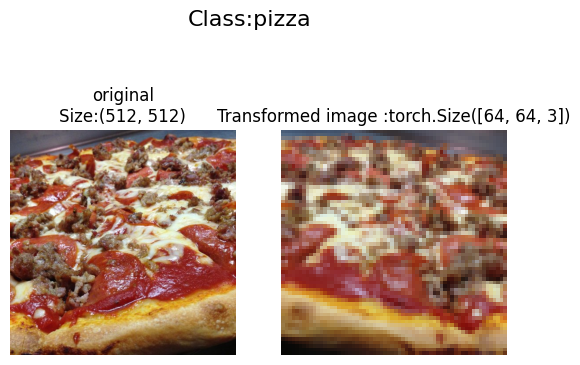

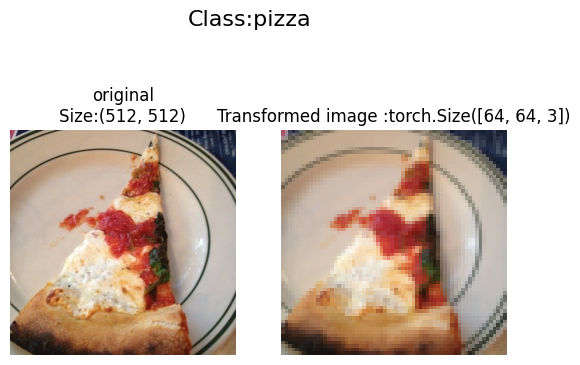

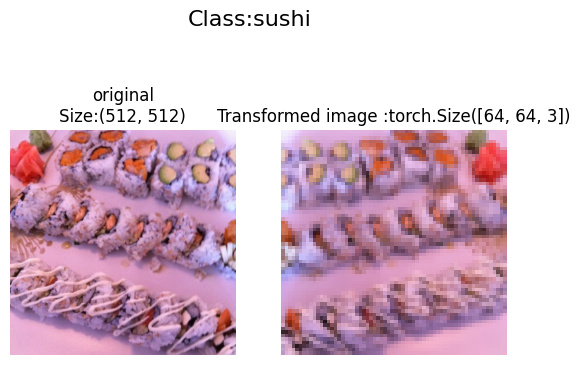

In [94]:
def plot_transformed_images(image_path,
                             transform,
                             n=3,
                             seed=42):
  if seed:
    random.seed(seed)
  random_image_path = random.sample(image_path, k=n)
  for image_path in random_image_path:
    with Image.open(image_path) as f:
      fig, ax = plt.subplots(nrows=1,ncols=2)
      ax[0].imshow(f)
      ax[0].set_title(f"original\nSize:{f.size}")
      ax[0].axis(False)

      transformed_image = transform(f).permute(1,2,0)#color, height,width
      ax[1].imshow(transformed_image)
      ax[1].set_title(f"Transformed image :{transformed_image.shape}")
      ax[1].axis(False)

      fig.suptitle(f"Class:{image_path.parent.stem}", fontsize=16)


plot_transformed_images(image_path=image_path_list,
                        transform=data_transform,
                        n=3,
                        seed=42)
